# Lab 4 — How many dimensions?

**Accompanies Lecture 5 (estimating the intrinsic dimension of data).**

You build the estimators from the lecture, check them against known answers, and then find the places where they break.

| # | Exercise | What you build |
|---|---|---|
| 1 | TwoNN from scratch | `twonn_mu`, `twonn_mle`, `pareto_slope` |
| 2 | The correlation integral, the scaling region, and a ball of yarn | `correlation_integral`, `local_slopes`, `region_slope`, `correlation_integral_anchored` |
| 3 | Local estimates and a mixture | `local_mle`, `arithmetic`, `harmonic` |
| 4 | The estimator zoo, then the scale probe | `run_estimators`, `winners`, `thinning_curve` |
| 5 | The dimension of a network's representation (take-home) | `layer_activations`, `layer_ids`, `make_untrained` |

Every exercise ends with an `assert` cell. If your code is correct, the notebook runs from top to bottom with no error. Exercises 1–4 are for the lab session; Exercise 5 takes about a minute of computing and can be done at home.


In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import skdim
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")
NAVY, TEAL, AMBER, MUTE = "#1E2761", "#1C7293", "#E8871E", "#6E7691"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| scikit-dimension", skdim.__version__)


numpy 1.26.4 | scikit-learn 1.3.2 | scikit-dimension 0.3.7


## Exercise 1 — TwoNN from scratch

From the lecture: if the points of a $D$-dimensional manifold form a Poisson process, then $\mu=r_2/r_1$ (the ratio of the distances to the second and the first neighbour) satisfies $P(\mu>x)=x^{-D}$. Two consequences you will use:

* the maximum-likelihood estimate is $\hat D = N/\sum_i\ln\mu_i$, and the unbiased version is $(N-1)/\sum_i\ln\mu_i$;
* $-\ln(1-F(\mu))=D\ln\mu$, where $F$ is the empirical distribution function of $\mu$: a straight line through the origin with slope $D$.

You write:

1. `twonn_mu(X)`: the array of ratios $r_2/r_1$, one per point. Use `NearestNeighbors(n_neighbors=3)` (column 0 of the result is the point itself). **Beware of repeated points**: if two points coincide then $r_1=0$, and ties ($r_2=r_1$) appear around them.
2. `twonn_mle(mu, unbiased=False)`.
3. `pareto_slope(mu)`: sort $\ln\mu$, use $F_i=i/N$ for $i=1,\dots,N-1$, and return the least-squares slope through the origin of $-\ln(1-F_i)$ against $\ln\mu_{(i)}$, that is $\sum xy/\sum x^2$.


In [2]:
# GIVEN: three sets of known dimension, 3000 points each
rng = np.random.default_rng(0); n = 3000
th = rng.uniform(0, 2 * np.pi, n); circ = np.zeros((n, 50)); circ[:, 0], circ[:, 1] = np.cos(th), np.sin(th)
v = rng.normal(size=(n, 3)); sph = v / np.linalg.norm(v, axis=1, keepdims=True)
cube5 = rng.uniform(size=(n, 5))
sets1 = {"circle in R^50 (D = 1)": (circ, 1), "sphere S2 (D = 2)": (sph, 2), "5-cube (D = 5)": (cube5, 5)}


In [3]:
# SOLUTION
def twonn_mu(X):
    X = np.unique(X, axis=0)                     # repeated points would give r1 = 0 and ties
    d, _ = NearestNeighbors(n_neighbors=3).fit(X).kneighbors(X)
    return d[:, 2] / d[:, 1]

def twonn_mle(mu, unbiased=False):
    n = len(mu)
    return (n - 1 if unbiased else n) / np.log(mu).sum()

def pareto_slope(mu):
    lm = np.sort(np.log(mu)); n = len(lm)
    F = np.arange(1, n) / n
    x, y = lm[:-1], -np.log(1 - F)
    return float((x * y).sum() / (x * x).sum())


In [4]:
# GIVEN: the estimates, and the trap of repeated points
res1 = {}
for name, (X, D) in sets1.items():
    mu = twonn_mu(X)
    res1[name] = dict(D=D, n=len(mu), mle=twonn_mle(mu), unb=twonn_mle(mu, True), par=pareto_slope(mu), med=float(np.median(mu)))
print(f"{'set':26s} {'MLE':>6s} {'unbiased':>9s} {'Pareto slope':>13s}   median mu vs 2^(1/D)")
for name, r in res1.items():
    print(f"{name:26s} {r['mle']:6.3f} {r['unb']:9.3f} {r['par']:13.3f}   {r['med']:.3f} vs {2 ** (1 / r['D']):.3f}")

dup = np.vstack([sph, sph[:300]])                # 300 of the 3000 points appear twice
d3, _ = NearestNeighbors(n_neighbors=3).fit(dup).kneighbors(dup)
with np.errstate(all="ignore"):
    naive = len(dup) / np.log(d3[:, 2] / d3[:, 1]).sum()
est_dup, est_clean = twonn_mle(twonn_mu(dup)), twonn_mle(twonn_mu(sph))
print(f"\nrepeated points: {(d3[:, 1] == 0).sum()} points have r1 = 0; the naive formula gives {naive:.3f}")
print(f"your estimate with the repeated points: {est_dup:.3f}; on the clean data: {est_clean:.3f}")


set                           MLE  unbiased  Pareto slope   median mu vs 2^(1/D)
circle in R^50 (D = 1)      1.037     1.037         1.056   1.984 vs 2.000
sphere S2 (D = 2)           2.008     2.008         1.994   1.410 vs 1.414
5-cube (D = 5)              4.528     4.526         4.453   1.162 vs 1.149

repeated points: 600 points have r1 = 0; the naive formula gives 0.000
your estimate with the repeated points: 2.008; on the clean data: 2.008


In [5]:
# CHECK
r = res1
assert 0.9 < r["circle in R^50 (D = 1)"]["mle"] < 1.15
assert 1.9 < r["sphere S2 (D = 2)"]["mle"] < 2.15
assert 4.2 < r["5-cube (D = 5)"]["mle"] < 4.8, "the 5-cube is underestimated: the boundary and the finite sample"
for name, x in r.items():
    assert abs(x["par"] - x["mle"]) < 0.15, f"{name}: the two estimators should agree"
    assert abs(x["med"] - 2 ** (1 / x["D"])) < 0.03, f"{name}: median mu should be close to 2^(1/D)"
    assert np.isclose(x["unb"], x["mle"] * (x["n"] - 1) / x["n"]), "unbiased = (N-1)/N times the MLE"
assert abs(est_dup - est_clean) < 0.1, "repeated points must not change the estimate (ties and r1 = 0 need care)"
print("Exercise 1 passed.")


Exercise 1 passed.


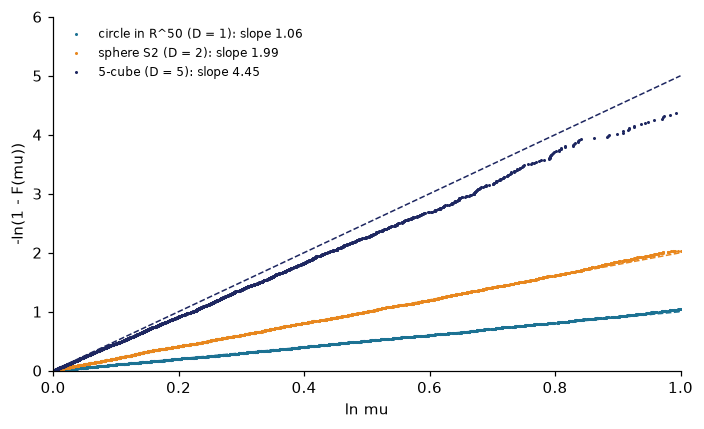

In [6]:
# GIVEN: the picture: a Pareto law is a straight line through the origin with slope D
fig, ax = plt.subplots(figsize=(6.5, 4))
for (name, (X, D)), col in zip(sets1.items(), (TEAL, AMBER, NAVY)):
    lm = np.sort(np.log(twonn_mu(X))); F = np.arange(1, len(lm) + 1) / (len(lm) + 1)
    ax.plot(lm, -np.log(1 - F), ".", ms=2, color=col, label=f"{name}: slope {res1[name]['par']:.2f}")
    ax.plot([0, 1], [0, D], "--", color=col, lw=1)
ax.set_xlim(0, 1); ax.set_ylim(0, 6); ax.set_xlabel("ln mu"); ax.set_ylabel("-ln(1 - F(mu))"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()


*Discuss:* the 5-cube gives about 4.5, not 5. Which two effects pull the estimate down? And why did the naive formula return exactly $0$ instead of an error message?

## Exercise 2 — The correlation integral, the scaling region, and a ball of yarn

The correlation integral $C(r)$ is the fraction of pairs of points at distance $\le r$. If $C(r)\propto r^D$, the slope of $\log C$ against $\log r$ is the dimension, but only in a **scaling region**.

You write:

1. `correlation_integral(X, radii)`: sort the pairwise distances (`pdist`) and use `np.searchsorted(..., side="right")`.
2. `local_slopes(radii, C)`: the slope of $\log_{10}C$ against $\log_{10}r$ at every radius (`np.gradient`).
3. `region_slope(radii, C, lo, hi)`: the least-squares slope using only the radii in $[lo,hi]$.
4. `correlation_integral_anchored(X, radii, n_anchor=4000, seed=1)`: for large $N$ you cannot compute all pairs. Pick `n_anchor` random points (`rng.choice`), build `cKDTree(anchors)` and `cKDTree(X)`, and use `tree_a.count_neighbors(tree_x, radii)`. It counts the (anchor, point) pairs within each radius **including each anchor paired with itself**, so subtract `n_anchor` and divide by `n_anchor * (len(X) - 1)`.

Part A uses a noisy circle and the Cantor set. In Part B you measure a simulated ball of yarn.


In [7]:
# GIVEN: a circle with noise 0.03 in R^3 (a "ball of yarn" in the simplest sense) and the Cantor set
rng = np.random.default_rng(0)
th = rng.uniform(0, 2 * np.pi, 3000)
yarn = np.column_stack([np.cos(th), np.sin(th), 0 * th]) + 0.03 * rng.normal(size=(3000, 3))
rs = np.geomspace(0.006, 3.0, 60)
digits = rng.integers(0, 2, size=(3000, 25)) * 2
cantor = (digits * 3.0 ** -np.arange(1, 26)).sum(1)[:, None]          # the middle-thirds Cantor set, dimension ln2/ln3 = 0.631
rc = np.geomspace(1e-5, 1e-1, 80)


In [8]:
# SOLUTION
def correlation_integral(X, radii):
    D = np.sort(pdist(X))
    return np.searchsorted(D, radii, side="right") / len(D)

def local_slopes(radii, C):
    return np.gradient(np.log10(C), np.log10(radii))

def region_slope(radii, C, lo, hi):
    m = (radii >= lo) & (radii <= hi)
    return float(np.polyfit(np.log10(radii[m]), np.log10(C[m]), 1)[0])

def correlation_integral_anchored(X, radii, n_anchor=4000, seed=1):
    rng = np.random.default_rng(seed)
    anchors = X[rng.choice(len(X), n_anchor, replace=False)]
    counts = cKDTree(anchors).count_neighbors(cKDTree(X), radii).astype(float)
    return (counts - n_anchor) / (n_anchor * (len(X) - 1))


In [9]:
# GIVEN: Part A
C_yarn = correlation_integral(yarn, rs)
s_small, s_mid = region_slope(rs, C_yarn, 0.006, 0.03), region_slope(rs, C_yarn, 0.3, 0.7)
print(f"noisy circle: slope for r in [0.006, 0.03] = {s_small:.2f};  for r in [0.3, 0.7] = {s_mid:.2f}")
C_can = correlation_integral(cantor, rc)
s_can, loc_can = region_slope(rc, C_can, 1e-5, 1e-1), local_slopes(rc, C_can)[3:-3]
s_short = region_slope(rc, C_can, rc[0], rc[3])
print(f"Cantor set: fit over four decades = {s_can:.3f};  local slope ranges from {loc_can.min():.2f} to {loc_can.max():.2f};  a fit over the first four radii only = {s_short:.2f}")


noisy circle: slope for r in [0.006, 0.03] = 2.89;  for r in [0.3, 0.7] = 1.04
Cantor set: fit over four decades = 0.632;  local slope ranges from 0.28 to 1.14;  a fit over the first four radii only = 0.96


In [10]:
# CHECK: Part A
assert s_small > 2.5, "at the scale of the noise the circle looks 3-dimensional"
assert 0.95 < s_mid < 1.15, "at larger scales it looks like a curve"
assert 0.55 < s_can < 0.70, "the Cantor set has dimension 0.631"
assert loc_can.max() - loc_can.min() > 0.5, "the local slope of the Cantor set oscillates"
assert s_short > 0.8, "a fit over less than one period of the oscillation is off"
print("Exercise 2, Part A passed.")


Exercise 2, Part A passed.


### Part B: a ball of yarn

A real ball of yarn is a long thread wound into a ball. `make_thread` simulates one: a smooth random curve (persistence length 0.1) with 100 000 points spaced 0.001 apart, pulled gently towards the centre so that it fills a ball, with Gaussian noise of 0.0004 for the thickness of the thread.

Compute $C(r)$ with your anchored function and read the dimension at several scales. Then thin the points and apply your TwoNN from Exercise 1 to see the same scales from the other side. (The simulation takes a few seconds.)


In [11]:
# GIVEN: the simulated ball of yarn (a few seconds)
def make_thread(N=100000, step=0.001, lp=0.1, sigma=0.0004, pull=12.0, seed=0):
    rng = np.random.default_rng(seed); delta = np.sqrt(2 * step / lp)
    p = np.zeros(3); t = rng.normal(size=3); t /= np.linalg.norm(t); P = np.empty((N, 3))
    for i in range(N):
        xi = rng.normal(size=3); xi -= xi.dot(t) * t
        t = t + delta * xi - pull * step * p; t /= np.linalg.norm(t); p = p + step * t; P[i] = p
    return P + sigma * rng.normal(size=(N, 3))

thread = make_thread()
radii_t = np.geomspace(2e-4, 3.0, 80)
C_t = correlation_integral_anchored(thread, radii_t)
C_t[C_t <= 0] = np.nan
loc_t = local_slopes(radii_t, C_t)
slope_at = lambda r: float(loc_t[np.argmin(np.abs(radii_t - r))])
print("scale r -> local slope")
for r0 in (0.0005, 0.002, 0.006, 0.016, 0.06, 0.1, 0.2, 0.35, 0.5, 1.0):
    print(f"   r = {r0:6.4f}: {slope_at(r0):5.2f}")


scale r -> local slope
   r = 0.0005:  2.83
   r = 0.0020:  1.71
   r = 0.0060:  1.18
   r = 0.0160:  1.42
   r = 0.0600:  2.41
   r = 0.1000:  2.54
   r = 0.2000:  2.51
   r = 0.3500:  2.07
   r = 0.5000:  1.40
   r = 1.0000:  0.04


In [12]:
# SOLUTION: thinning the thread with TwoNN
def thin_twonn(X, ns, draws=5):
    out = []
    for n in ns:
        k = draws if n < len(X) else 1
        out.append(float(np.mean([twonn_mle(twonn_mu(X[np.random.default_rng(s).choice(len(X), n, replace=False)])) for s in range(k)])))
    return out


In [13]:
# GIVEN
ns_t = [100000, 25000, 6000, 1500, 400, 100]
th_t = thin_twonn(thread, ns_t)
print("TwoNN of the thread thinned to n points:", {n: round(float(v), 2) for n, v in zip(ns_t, th_t)})


TwoNN of the thread thinned to n points: {100000: 2.23, 25000: 1.56, 6000: 1.3, 1500: 1.47, 400: 1.97, 100: 2.57}


In [14]:
# CHECK: Part B
assert slope_at(0.0005) > 2.5, "inside the thickness of the thread: about 3"
assert 1.0 < slope_at(0.006) < 1.4, "along the thread: a curve"
assert slope_at(0.1) > 2.1 and slope_at(0.2) > 2.1, "where the thread fills the ball"
assert slope_at(1.0) < 0.2, "beyond the ball it is a point"
assert min(th_t) < 1.6 and int(np.argmin(th_t)) in (1, 2, 3, 4), "thinning reaches the thread's dimension at an intermediate scale"
assert th_t[-1] > 2.0, "and rises again towards the ball"
print("Exercise 2 passed.")


Exercise 2 passed.


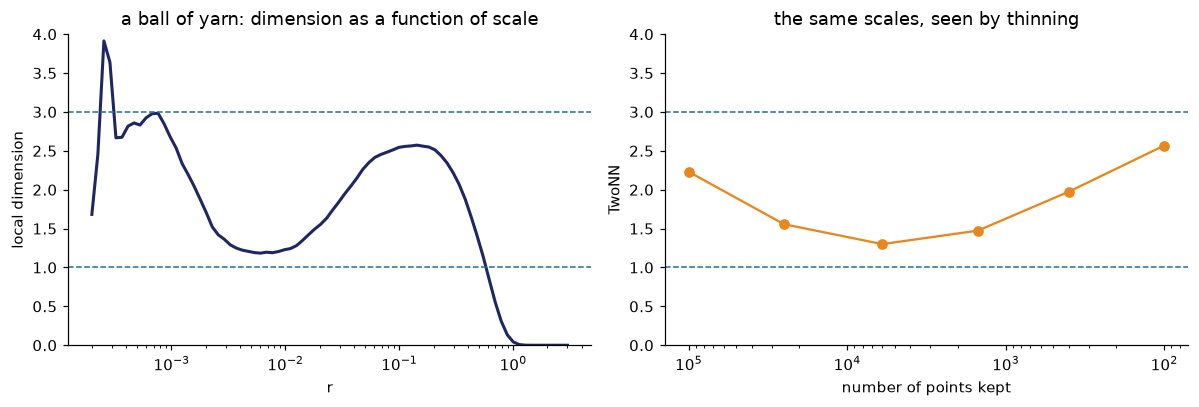

In [15]:
# GIVEN: the pictures
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].semilogx(radii_t, loc_t, color=NAVY, lw=2); ax[0].axhline(1, ls="--", color=TEAL, lw=1); ax[0].axhline(3, ls="--", color=TEAL, lw=1)
ax[0].set_xlabel("r"); ax[0].set_ylabel("local dimension"); ax[0].set_ylim(0, 4); ax[0].set_title("a ball of yarn: dimension as a function of scale")
ax[1].semilogx(ns_t, th_t, "o-", color=AMBER); ax[1].axhline(1, ls="--", color=TEAL, lw=1); ax[1].axhline(3, ls="--", color=TEAL, lw=1)
ax[1].invert_xaxis(); ax[1].set_xlabel("number of points kept"); ax[1].set_ylabel("TwoNN"); ax[1].set_ylim(0, 4); ax[1].set_title("the same scales, seen by thinning")
plt.tight_layout(); plt.show()


*Discuss:* the ball regime reaches about $2.5$, not $3$. Why? (Hint: compare the typical distance between neighbouring strands with the radius of the ball.) What would a **tightly** wound ball of yarn look like on these plots?

## Exercise 3 — Local estimates and a mixture

The same Poisson argument for $k$ neighbours gives a local estimate at every point (Levina and Bickel): with $T_1\le\dots\le T_k$ the distances to the neighbours,

$$\hat m(x)=\Big[\frac1{k-1}\sum_{j<k}\ln\frac{T_k}{T_j}\Big]^{-1}.$$

You write:

1. `local_mle(X, k=10)`: the array of $\hat m(x)$, one per point (`NearestNeighbors(n_neighbors=k+1)`, drop column 0).
2. `arithmetic(m)`: the mean of the local estimates.
3. `harmonic(m)`: the inverse of the mean of the inverses.


In [16]:
# GIVEN: a sphere, a square, a 3-cube, and a mixture of a circle (D = 1) and a sphere (D = 2)
rng = np.random.default_rng(0)
v = rng.normal(size=(3000, 3)); S2 = v / np.linalg.norm(v, axis=1, keepdims=True)
square = rng.uniform(size=(3000, 2)); cube3 = rng.uniform(size=(3000, 3))
t = rng.uniform(0, 2 * np.pi, 1500); circle3 = np.column_stack([np.cos(t), np.sin(t), 0 * t])
w = rng.normal(size=(1500, 3)); sphere3 = w / np.linalg.norm(w, axis=1, keepdims=True) + np.array([4.0, 0, 0])
mixture = np.vstack([circle3, sphere3])


In [17]:
# SOLUTION
def local_mle(X, k=10):
    d, _ = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)
    d = d[:, 1:]
    return (k - 1) / np.log(d[:, -1:] / d[:, :-1]).sum(1)

def arithmetic(m): return float(np.mean(m))
def harmonic(m): return float(1 / np.mean(1 / m))


In [18]:
# GIVEN
for name, X, D in (("sphere S2", S2, 2), ("square", square, 2), ("3-cube", cube3, 3)):
    m = local_mle(X)
    print(f"{name:10s} (D = {D}): arithmetic mean {arithmetic(m):.3f}, harmonic mean {harmonic(m):.3f}")
mm = local_mle(mixture)
union = twonn_mle(twonn_mu(mixture))
print(f"\nmixture of a circle and a sphere: TwoNN on the union = {union:.2f}")
print(f"local estimates (harmonic mean) on the circle part: {harmonic(mm[:1500]):.2f}, on the sphere part: {harmonic(mm[1500:]):.2f}")


sphere S2  (D = 2): arithmetic mean 2.255, harmonic mean 2.002
square     (D = 2): arithmetic mean 2.203, harmonic mean 1.943
3-cube     (D = 3): arithmetic mean 3.279, harmonic mean 2.927

mixture of a circle and a sphere: TwoNN on the union = 1.32
local estimates (harmonic mean) on the circle part: 0.98, on the sphere part: 2.01


In [19]:
# CHECK
m_S2, m_sq, m_c3 = local_mle(S2), local_mle(square), local_mle(cube3)
assert arithmetic(m_S2) > 2.15, "averaging the local estimates overestimates (Jensen)"
assert 1.9 < harmonic(m_S2) < 2.1
assert 1.85 < harmonic(m_sq) < 2.1
assert 2.75 < harmonic(m_c3) < 3.1
assert 1.15 < union < 1.5, "one number for a mixture lies between the parts"
assert 0.85 < harmonic(mm[:1500]) < 1.15 and 1.85 < harmonic(mm[1500:]) < 2.2, "local estimates recover the parts"
print("Exercise 3 passed.")


Exercise 3 passed.


*Discuss:* $\sum_j\ln(T_k/T_j)$ is Gamma-distributed with rate $D$. Use that to explain why averaging $\hat m$ overestimates $D$ while averaging $1/\hat m$ does not. Which of the two numbers (the union estimate, or the two local ones) would you report for the mixture?

## Exercise 4 — The estimator zoo, then the scale probe

**Part A.** Run six estimators from scikit-dimension on five data sets with known dimension. You write:

1. `run_estimators(X)`: a dictionary `name -> estimate` for the estimators in `EST` (create each with `f()`, then `.fit(X).dimension_`).
2. `winners(table, truth)`: for every data set, the name of the estimator with the smallest **relative** error $|\hat D-D|/D$.

**Part B.** Thinning the points raises the typical neighbour distance, so it probes a larger scale. You write `thinning_curve(X, ns, draws=10)`: for every $n$ in `ns`, the mean of your TwoNN over `draws` random subsets of $n$ points (`np.random.default_rng(s).choice(len(X), n, replace=False)`, $s=0,\dots,$`draws-1`).


In [20]:
# GIVEN: five data sets (1500 points each)
EST = {"lPCA": skdim.id.lPCA, "MLE": skdim.id.MLE, "TwoNN": skdim.id.TwoNN, "CorrInt": skdim.id.CorrInt, "TLE": skdim.id.TLE, "FisherS": skdim.id.FisherS}
N = 1500; rng = np.random.default_rng(3)
def sphere_(d, amb):
    v = rng.normal(size=(N, d + 1)); v /= np.linalg.norm(v, axis=1, keepdims=True); X = np.zeros((N, amb)); X[:, :d + 1] = v; return X
def roll():
    t = rng.uniform(1.5 * np.pi, 4.5 * np.pi, N); h = rng.uniform(0, 14, N); return np.column_stack([t * np.cos(t), h, t * np.sin(t)])
def helix():
    t = rng.uniform(0, 4 * np.pi, N); return np.column_stack([np.cos(t), np.sin(t), t / 5])
def noisy_circle():
    th = rng.uniform(0, 2 * np.pi, N); X = np.zeros((N, 50)); X[:, 0], X[:, 1] = np.cos(th), np.sin(th); return X + 0.02 * rng.normal(size=X.shape)
data4 = {"S2": sphere_(2, 3), "S9": sphere_(9, 10), "Swiss roll": roll(), "helix": helix(), "noisy circle": noisy_circle()}
truth4 = {"S2": 2, "S9": 9, "Swiss roll": 2, "helix": 1, "noisy circle": 1}


In [21]:
# SOLUTION
def run_estimators(X):
    return {name: float(f().fit(X).dimension_) for name, f in EST.items()}

def winners(table, truth):
    return {ds: min(row, key=lambda k: abs(row[k] - truth[ds]) / truth[ds]) for ds, row in table.items()}

def thinning_curve(X, ns, draws=10):
    return [float(np.mean([twonn_mle(twonn_mu(X[np.random.default_rng(s).choice(len(X), n, replace=False)])) for s in range(draws)])) for n in ns]


In [22]:
# GIVEN: Part A
table4 = {name: run_estimators(X) for name, X in data4.items()}
print(f"{'':14s}" + "".join(f"{k:>9s}" for k in EST) + "   winner")
win = winners(table4, truth4)
for name, row in table4.items():
    print(f"{name + ' (' + str(truth4[name]) + ')':14s}" + "".join(f"{v:9.2f}" for v in row.values()) + f"   {win[name]}")


                   lPCA      MLE    TwoNN  CorrInt      TLE  FisherS   winner
S2 (2)             3.00     1.99     1.90     1.99     2.18     2.99   CorrInt
S9 (9)            10.00     8.24     8.55     8.03     9.20    10.07   TLE
Swiss roll (2)     3.00     1.93     2.02     1.93     2.11     2.88   TwoNN
helix (1)          3.00     0.99     1.01     0.99     1.08     2.57   TwoNN
noisy circle (1)     2.00    14.86    23.81    11.46    14.19     1.97   FisherS


In [23]:
# CHECK: Part A
t4 = table4
for ds in ("S2", "Swiss roll"):
    assert t4[ds]["lPCA"] >= 2.9, f"{ds}: linear PCA counts 3 directions of a curved surface"
    for e in ("MLE", "TwoNN", "CorrInt"):
        assert abs(t4[ds][e] - 2) / 2 < 0.15, f"{ds}: {e} should be within 15% of 2"
assert t4["S9"]["lPCA"] >= 9.9 and all(t4["S9"][e] < 9 for e in ("MLE", "TwoNN", "CorrInt")), "S9: the local estimators underestimate"
assert all(t4["noisy circle"][e] > 5 for e in ("MLE", "TwoNN", "CorrInt")) and t4["noisy circle"]["lPCA"] <= 2.5, "noise inflates the local estimators"
assert len(set(win.values())) >= 3, "no estimator wins everywhere"
print("Exercise 4, Part A passed.")


Exercise 4, Part A passed.


In [24]:
# GIVEN: Part B: a circle in R^50, without and with noise (0.005 per coordinate), thinned
Nb = 6000; ns4 = [6000, 1500, 375, 95, 50, 25]
def circle50(noise):
    rng = np.random.default_rng(0); th = rng.uniform(0, 2 * np.pi, Nb); X = np.zeros((Nb, 50)); X[:, 0], X[:, 1] = np.cos(th), np.sin(th)
    return X + noise * rng.normal(size=X.shape)
curve_clean, curve_noisy = thinning_curve(circle50(0.0), ns4), thinning_curve(circle50(0.005), ns4)
print("n          :", ns4); print("no noise   :", np.round(curve_clean, 2)); print("noise 0.005:", np.round(curve_noisy, 2))


n          : [6000, 1500, 375, 95, 50, 25]
no noise   : [1.02 1.01 1.01 1.04 0.95 0.94]
noise 0.005: [23.59 19.05 11.6   3.52  2.01  1.45]


In [25]:
# CHECK: Part B
assert all(0.85 < v < 1.2 for v in curve_clean), "without noise the estimate is 1 at every scale"
assert curve_noisy[0] > 15, "with noise, the smallest scale looks high-dimensional"
assert curve_noisy[4] < 4 and curve_noisy[5] < 4, "thinning probes a larger scale, where the circle is visible"
assert curve_noisy[0] > curve_noisy[2] > curve_noisy[3], "the estimate falls as the scale grows"
print("Exercise 4 passed.")


Exercise 4 passed.


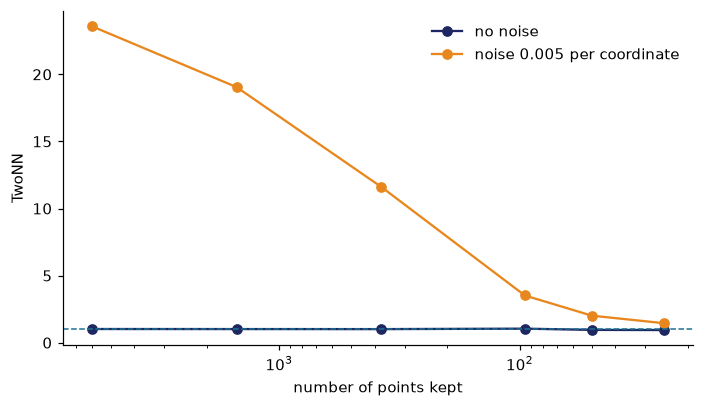

In [26]:
# GIVEN: the picture
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(ns4, curve_clean, "o-", color=NAVY, label="no noise"); ax.plot(ns4, curve_noisy, "o-", color=AMBER, label="noise 0.005 per coordinate")
ax.axhline(1, ls="--", color=TEAL, lw=1); ax.set_xscale("log"); ax.invert_xaxis(); ax.set_xlabel("number of points kept"); ax.set_ylabel("TwoNN"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()


*Discuss:* which estimator would you trust for (a) a clean curved surface, (b) data with a lot of noise, (c) a fractal? Use the table, not your memory of the lecture. Why does TwoNN react to noise first?

## Exercise 5 (take-home) — The dimension of a network's representation

Ansuini et al. (2019) found that the intrinsic dimension of the last hidden layers of a network that generalises is low, and that it stays high for a network trained on random labels or left untrained. You reproduce this in miniature on the handwritten digits. Training takes about a minute.

You write:

1. `layer_activations(net, X)`: the list of activations at the input and after every hidden layer. `MLPClassifier` stores the weights in `net.coefs_` and the biases in `net.intercepts_`; use ReLU after each hidden layer (all but the last entry).
2. `layer_ids(net, X)`: the TwoNN dimension of each of those activation sets (use your Exercise 1 functions; ReLU can map different inputs to the same activation, and `twonn_mu` handles that).
3. `make_untrained(cfg, Xtr, ytr)`: a network whose weights are the **random initial ones**. `fit` always makes at least one pass, so you have to make that pass change nothing. *Check your control: it has to behave like an untrained network.*


In [27]:
# GIVEN: the digits, a 60/40 split, and two trained networks (about one minute)
Xd = load_digits().data / 16.0; yd = load_digits().target
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.4, random_state=0, stratify=yd)
yperm = np.random.default_rng(0).permutation(ytr)
cfg = dict(hidden_layer_sizes=(256, 256, 256), activation="relu", random_state=0, alpha=0.0, solver="adam", learning_rate_init=3e-3)
net_real = MLPClassifier(max_iter=600, **cfg).fit(Xtr, ytr)
net_random = MLPClassifier(max_iter=3000, tol=1e-7, n_iter_no_change=200, **cfg).fit(Xtr, yperm)   # memorises the random labels
print("real labels   : train accuracy %.3f, test accuracy %.3f" % (net_real.score(Xtr, ytr), net_real.score(Xte, yte)))
print("random labels : train accuracy %.3f, test accuracy %.3f" % (net_random.score(Xtr, yperm), net_random.score(Xte, yte)))


real labels   : train accuracy 1.000, test accuracy 0.978
random labels : train accuracy 1.000, test accuracy 0.078


In [28]:
# SOLUTION
def layer_activations(net, X):
    out, a = [X], X
    for W, b in zip(net.coefs_[:-1], net.intercepts_[:-1]):
        a = np.maximum(a @ W + b, 0)
        out.append(a)
    return out

def layer_ids(net, X):
    return [float(twonn_mle(twonn_mu(A))) for A in layer_activations(net, X)]

def make_untrained(cfg, Xtr, ytr):
    return MLPClassifier(max_iter=1, **{**cfg, "learning_rate_init": 1e-12}).fit(Xtr, ytr)


In [29]:
# GIVEN
net_untrained = make_untrained(cfg, Xtr, ytr)
print("untrained     : test accuracy %.3f" % net_untrained.score(Xte, yte))
nets = {"real labels": net_real, "random labels (memorised)": net_random, "untrained": net_untrained}
ids5 = {name: layer_ids(net, Xte) for name, net in nets.items()}
def pca95(A): return int(np.searchsorted(np.cumsum(PCA().fit(A).explained_variance_ratio_), 0.95) + 1)
lin5 = {name: [pca95(A) for A in layer_activations(net, Xte)] for name, net in nets.items()}
print(f"\n{'':28s}  ID per layer (input, hidden 1-3)          PCA components for 95% variance")
for name in nets: print(f"{name:28s}  {np.round(ids5[name], 2)}   {lin5[name]}")


untrained     : test accuracy 0.047

                              ID per layer (input, hidden 1-3)          PCA components for 95% variance
real labels                   [7.75 7.92 6.72 5.83]   [28, 31, 11, 8]
random labels (memorised)     [7.75 8.24 7.81 7.88]   [28, 75, 82, 27]
untrained                     [7.75 8.17 8.5  8.55]   [28, 47, 57, 61]


In [30]:
# CHECK
assert net_real.score(Xtr, ytr) >= 0.99 and net_real.score(Xte, yte) >= 0.95
assert net_random.score(Xtr, yperm) >= 0.99 and net_random.score(Xte, yte) <= 0.2, "the control must memorise the random labels and not generalise"
assert net_untrained.score(Xte, yte) <= 0.25, "an untrained network is at chance level; one epoch of training is already too much"
last = {k: v[-1] for k, v in ids5.items()}
assert last["real labels"] < last["random labels (memorised)"] - 1.0, last
assert last["real labels"] < last["untrained"] - 1.0, last
assert lin5["random labels (memorised)"][1] > 5 * ids5["random labels (memorised)"][1], "linear dimension is a different quantity from the intrinsic one"
print("Exercise 5 passed.")


Exercise 5 passed.


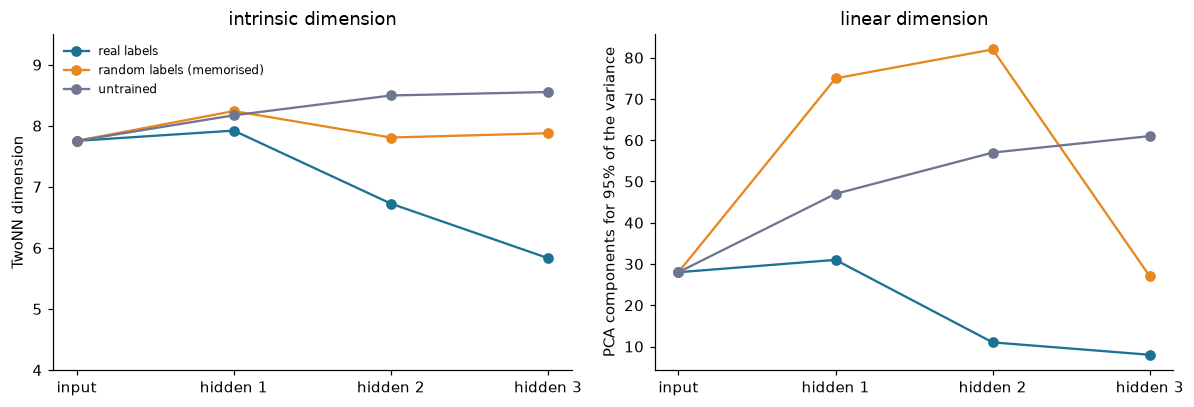

In [31]:
# GIVEN: the picture
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); labels = ["input", "hidden 1", "hidden 2", "hidden 3"]
for (name, v), col in zip(ids5.items(), (TEAL, AMBER, MUTE)): ax[0].plot(labels, v, "o-", color=col, label=name)
ax[0].set_ylabel("TwoNN dimension"); ax[0].set_ylim(4, 9.5); ax[0].legend(frameon=False, fontsize=8); ax[0].set_title("intrinsic dimension")
for (name, v), col in zip(lin5.items(), (TEAL, AMBER, MUTE)): ax[1].plot(labels, v, "o-", color=col, label=name)
ax[1].set_ylabel("PCA components for 95% of the variance"); ax[1].set_title("linear dimension")
plt.tight_layout(); plt.show()


*Discuss:* in the first version of this check the "untrained" network was trained for one epoch and had 86% accuracy. What would that have done to the conclusion? And why does the linear dimension of the memorising network peak in the middle layers while its intrinsic dimension does not?

---
### That is the whole lab.
